# 3. Csapattag – Éves Dinamikus Szimuláció és Munkaközeg-optimalizálás
Ertl Hanna (SPH4U7)

Ez a notebook végzi el a 8760 órás idősoros szimulációt a PVGIS TMY időjárási adatsor alapján, figyelembe véve a segédüzemi fogyasztásokat (kútszivattyúzás, kondenzátorventilátorok, generátorveszteség). 
Végigsöpri a megengedett elpárolgási nyomástartományt a 3 munkaközegre (R245fa, R1233zd(E), R600a), megkeresi a maximális éves megawattórát (MWh) adó optimális nyomásszinteket, és vizualizálja az éves termelést.

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
from CoolProp.CoolProp import PropsSI
from orc_thermo import DEFAULT_FLUIDS, calculate_orc

# --- 1. Rendszer paraméterek (Bartal és Milán modelljéből) ---
DATA_PATH = Path("output/hourly_inputs.csv")
T_SOURCE_C = 115.0         # Primer kútfej belépő [°C]
M_BRINE_WELL = 40.0        # Kútonkénti tömegáram [kg/s]
N_WELLS = 14               # Termelő kútpár szám (Bartal méretezése)
ETA_TURBINE = 0.80         # Milán feltevése
ETA_PUMP = 0.70            # Milán feltevése
ETA_GEN = 0.96             # Generátor hatásfok

# Segédüzemi paraméterek (Hanna feladata a rendszermodellhez)
WELL_PUMP_SPECIFIC_KWH_PER_M3 = 0.65   # Kútszivattyúzás fajlagos fogyasztása [kWh/m3 víz]
RHO_WATER = 970.0                      # Víz sűrűsége ~100 °C-on [kg/m3]
FAN_POWER_FRACTION_Q_COND = 0.018      # Ventilátor teljesítmény a kondenzátor hőáramához képest (~1.8%)

def get_parasitic_well_pumps_kw(m_brine_total_kg_s: float) -> float:
    """Kútszivattyúzási igény (termelés + visszasajtolás) [kW]."""
    v_dot_m3_s = m_brine_total_kg_s / RHO_WATER
    v_dot_m3_h = v_dot_m3_s * 3600.0
    return v_dot_m3_h * WELL_PUMP_SPECIFIC_KWH_PER_M3

def run_single_hour(fluid: str, p_evap_bar: float, t_air_c: float) -> dict:
    """Kiszámítja 1 óra nettó erőművi kimenetét a teljes kútrendszerre."""
    try:
        res = calculate_orc(
            fluid=fluid,
            T_source_C=T_SOURCE_C,
            T_air_C=t_air_c,
            m_brine_kg_s=M_BRINE_WELL,
            p_evap_bar=p_evap_bar,
            eta_turbine=ETA_TURBINE,
            eta_pump=ETA_PUMP,
        )
    except (ValueError, AssertionError):
        return None

    perf = res["performance"]
    # 1 kútra jutó mechanikai ciklusteljesítmény
    p_cycle_well_kw = perf["P_cycle_net_kW"]
    q_cond_well_kw = perf["Q_condenser_kW"]

    # Felskálázás N_WELLS-re és generátorveszteség
    p_gen_gross_kw = (p_cycle_well_kw * N_WELLS) * ETA_GEN
    q_cond_total_kw = q_cond_well_kw * N_WELLS

    # Segédüzemek levonása
    p_fan_kw = q_cond_total_kw * FAN_POWER_FRACTION_Q_COND
    p_well_pump_kw = get_parasitic_well_pumps_kw(M_BRINE_WELL * N_WELLS)

    p_net_power_kw = max(0.0, p_gen_gross_kw - p_fan_kw - p_well_pump_kw)

    return {
        "P_net_kw": p_net_power_kw,
        "P_gross_kw": p_gen_gross_kw,
        "P_aux_kw": p_fan_kw + p_well_pump_kw,
        "T_brine_out_C": perf["T_brine_out_C"],
    }

In [19]:
print(f"Adatok beolvasása innen: {DATA_PATH} ...")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"A(z) {DATA_PATH} fájl nem található! Futtasd előbb Bartal project.ipynb kódját.")

df_weather = pd.read_csv(DATA_PATH)
t_air_series = df_weather["T_air"].to_numpy()

# Lehetséges környezeti hőmérsékleti tartomány Szegedre (-10 °C-tól 40 °C-ig)
t_grid = np.linspace(t_air_series.min(), t_air_series.max(), 35)

results_overview = []
hourly_profiles = {}  # <--- 1. ITT HOZZUK LÉTRE AZ ÜRES SZÓTÁRAT
best_overall_case = None
max_overall_mwh = -1.0

print("\n--- ÉVES SZIMULÁCIÓ ÉS NYOMÁSSÖPRÉS INDÍTÁSA (8760 ÓRA) ---")

for fluid in DEFAULT_FLUIDS:
    # Fizikailag értelmes elpárolgási nyomástartomány kitűzése a fluidumhoz
    p_crit_bar = PropsSI("PCRIT", fluid) / 1e5
    # 55 °C-tól 105 °C-ig terjedő forráspont-tartomány keresése
    p_min_bar = PropsSI("P", "T", 55.0 + 273.15, "Q", 0, fluid) / 1e5
    p_max_bar = min(p_crit_bar * 0.90, PropsSI("P", "T", 102.0 + 273.15, "Q", 0, fluid) / 1e5)
    
    p_sweep = np.linspace(p_min_bar, p_max_bar, 25)
    best_fluid_mwh = -1.0
    best_p_opt = None
    best_hourly_profile = None

    print(f"\n[{fluid}] elemzése: {p_sweep.min():.2f} bar -> {p_sweep.max():.2f} bar tartományban...")

    for p_test in p_sweep:
        # Interpolációs tábla készítése az adott nyomáshoz a sebesség végett
        p_net_lookup = []
        valid = True
        for t_amb in t_grid:
            out = run_single_hour(fluid, p_test, t_amb)
            if out is None:
                valid = False
                break
            p_net_lookup.append(out["P_net_kw"])
        
        if not valid:
            continue

        # 8760 órás profil kiszámítása interpolációval
        hourly_p_net_kw = np.interp(t_air_series, t_grid, p_net_lookup)
        annual_mwh = hourly_p_net_kw.sum() / 1000.0

        if annual_mwh > best_fluid_mwh:
            best_fluid_mwh = annual_mwh
            best_p_opt = p_test
            best_hourly_profile = hourly_p_net_kw

    # <--- 2. ITT MENTJÜK EL AZ ADOTT KÖZEG LEGJOBB PROFILJÁT:
    hourly_profiles[fluid] = best_hourly_profile

    results_overview.append({
        "Munkaközeg": fluid,
        "Optimális p_evap [bar]": best_p_opt,
        "Éves Termelés [MWh]": best_fluid_mwh,
        "Átlagos P_nettó [MW]": (best_fluid_mwh * 1000.0) / 8760.0 / 1000.0,
        "Csúcs P (tél) [MW]": best_hourly_profile.max() / 1000.0 if best_hourly_profile is not None else 0,
        "Min P (nyár) [MW]": best_hourly_profile.min() / 1000.0 if best_hourly_profile is not None else 0,
    })

    if best_fluid_mwh > max_overall_mwh:
        max_overall_mwh = best_fluid_mwh
        best_overall_case = {
            "fluid": fluid,
            "p_evap_opt_bar": best_p_opt,
            "hourly_profile": best_hourly_profile,
        }

# Eredménytábla elkészítése
comparison_df = pd.DataFrame(results_overview).set_index("Munkaközeg")
print("\nA szimuláció sikeresen befejeződött.")

Adatok beolvasása innen: output/hourly_inputs.csv ...

--- ÉVES SZIMULÁCIÓ ÉS NYOMÁSSÖPRÉS INDÍTÁSA (8760 ÓRA) ---

[R245fa] elemzése: 4.00 bar -> 13.22 bar tartományban...

[R1233zd(E)] elemzése: 3.40 bar -> 10.90 bar tartományban...

[R600a] elemzése: 7.73 bar -> 20.61 bar tartományban...

A szimuláció sikeresen befejeződött.


In [20]:
comparison_df.style.format({
    "Optimális p_evap [bar]": "{:.2f}",
    "Éves Termelés [MWh]": "{:,.2f}",
    "Átlagos P_nettó [MW]": "{:.2f}",
    "Csúcs P (tél) [MW]": "{:.2f}",
    "Min P (nyár) [MW]": "{:.2f}",
}).set_caption("Geotermikus ORC erőmű éves dinamikus szimulációjának összehasonlító eredményei (14 kútpár)")

,Optimális p_evap [bar],Éves Termelés [MWh],Átlagos P_nettó [MW],Csúcs P (tél) [MW],Min P (nyár) [MW]
Munkaközeg,,,,,
R245fa,6.69,"53,793.48",6.14,9.45,1.21
R1233zd(E),5.59,"52,987.82",6.05,9.27,1.21
R600a,12.02,"53,733.66",6.13,9.34,1.26


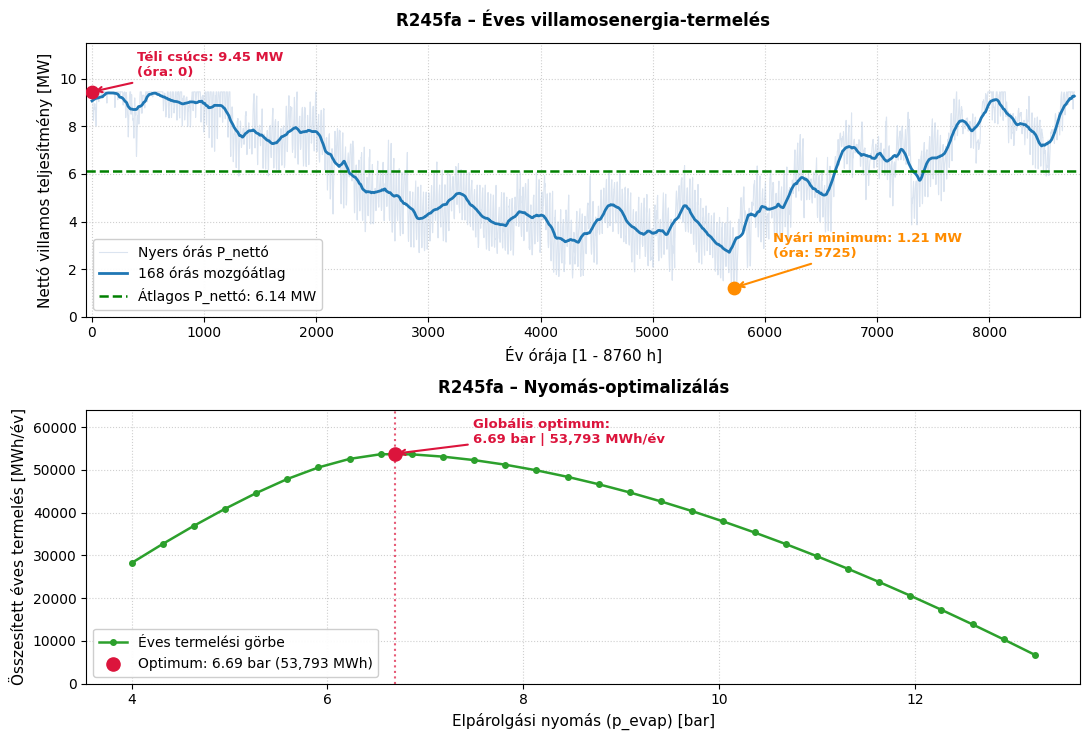

In [36]:
import matplotlib.pyplot as plt

# --- 1. R245fa annual data preparation ---
target_fluid = "R245fa"
p_hourly_mw = best_overall_case["hourly_profile"] / 1000.0  # kW -> MW

p_peak = p_hourly_mw.max()
p_min = p_hourly_mw.min()
p_mean = p_hourly_mw.mean()

idx_peak = int(np.argmax(p_hourly_mw))
idx_min = int(np.argmin(p_hourly_mw))

# --- 2. Figure setup ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5))

# --- TOP PLOT: Annual Net Power Profile ---
ax1.plot(p_hourly_mw, color="#b0c4de", alpha=0.45, lw=0.8, label="Nyers órás P_nettó")
p_smooth = pd.Series(p_hourly_mw).rolling(window=168, min_periods=1, center=True).mean()
ax1.plot(p_smooth, color="#1f77b4", lw=2, label="168 órás mozgóátlag")

# Mean reference line
ax1.axhline(p_mean, color="green", linestyle="--", lw=1.8, 
            label=f"Átlagos P_nettó: {p_mean:.2f} MW")

# Winter peak point and annotation (without bounding box)
ax1.scatter(idx_peak, p_peak, color="crimson", s=80, zorder=5)
ax1.annotate(f"Téli csúcs: {p_peak:.2f} MW\n(óra: {idx_peak})", 
             xy=(idx_peak, p_peak), xytext=(400, 10.1),
             arrowprops=dict(facecolor="crimson", edgecolor="crimson", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="crimson")

# Summer minimum point and annotation (without bounding box)
ax1.scatter(idx_min, p_min, color="darkorange", s=80, zorder=5)
ax1.annotate(f"Nyári minimum: {p_min:.2f} MW\n(óra: {idx_min})", 
             xy=(idx_min, p_min), xytext=(idx_min + 350, 2.5),
             arrowprops=dict(facecolor="darkorange", edgecolor="darkorange", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="darkorange")

ax1.set_title(f"R245fa – Éves villamosenergia-termelés", 
              fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("Év órája [1 - 8760 h]", fontsize=11)
ax1.set_ylabel("Nettó villamos teljesítmény [MW]", fontsize=11)
ax1.set_xlim(-50, 8810)
ax1.set_ylim(0, 11.5)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower left", framealpha=0.95)

# --- BOTTOM PLOT: Pressure Optimization Curve (p_evap sweep) ---
p_crit_bar = PropsSI("PCRIT", target_fluid) / 1e5
p_min_bar = PropsSI("P", "T", 55.0 + 273.15, "Q", 0, target_fluid) / 1e5
p_max_bar = min(p_crit_bar * 0.90, PropsSI("P", "T", 102.0 + 273.15, "Q", 0, target_fluid) / 1e5)
p_curve_sweep = np.linspace(p_min_bar, p_max_bar, 30)

mwh_curve = []
valid_p = []

for p_test in p_curve_sweep:
    p_net_lookup = []
    valid = True
    for t_amb in t_grid:
        out = run_single_hour(target_fluid, p_test, t_amb)
        if out is None:
            valid = False
            break
        p_net_lookup.append(out["P_net_kw"])
    if valid:
        mwh = (np.interp(t_air_series, t_grid, p_net_lookup)).sum() / 1000.0
        mwh_curve.append(mwh)
        valid_p.append(p_test)

opt_p = best_overall_case["p_evap_opt_bar"]
opt_mwh = max_overall_mwh

ax2.plot(valid_p, mwh_curve, color="#2ca02c", marker="o", markersize=4, lw=1.8, label="Éves termelési görbe")
ax2.scatter(opt_p, opt_mwh, color="crimson", s=90, zorder=5, label=f"Optimum: {opt_p:.2f} bar ({opt_mwh:,.0f} MWh)")
ax2.axvline(opt_p, color="crimson", linestyle=":", alpha=0.7)

# Optimum annotation (without bounding box)
ax2.annotate(f"Globális optimum:\n{opt_p:.2f} bar | {opt_mwh:,.0f} MWh/év", 
             xy=(opt_p, opt_mwh), xytext=(opt_p + 0.8, opt_mwh + 2500),
             arrowprops=dict(facecolor="crimson", edgecolor="crimson", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="crimson")

ax2.set_title("R245fa – Nyomás-optimalizálás", 
              fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("Elpárolgási nyomás (p_evap) [bar]", fontsize=11)
ax2.set_ylabel("Összesített éves termelés [MWh/év]", fontsize=11)
ax2.set_ylim(0, 64000)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", framealpha=0.95)

plt.tight_layout()
plt.show()

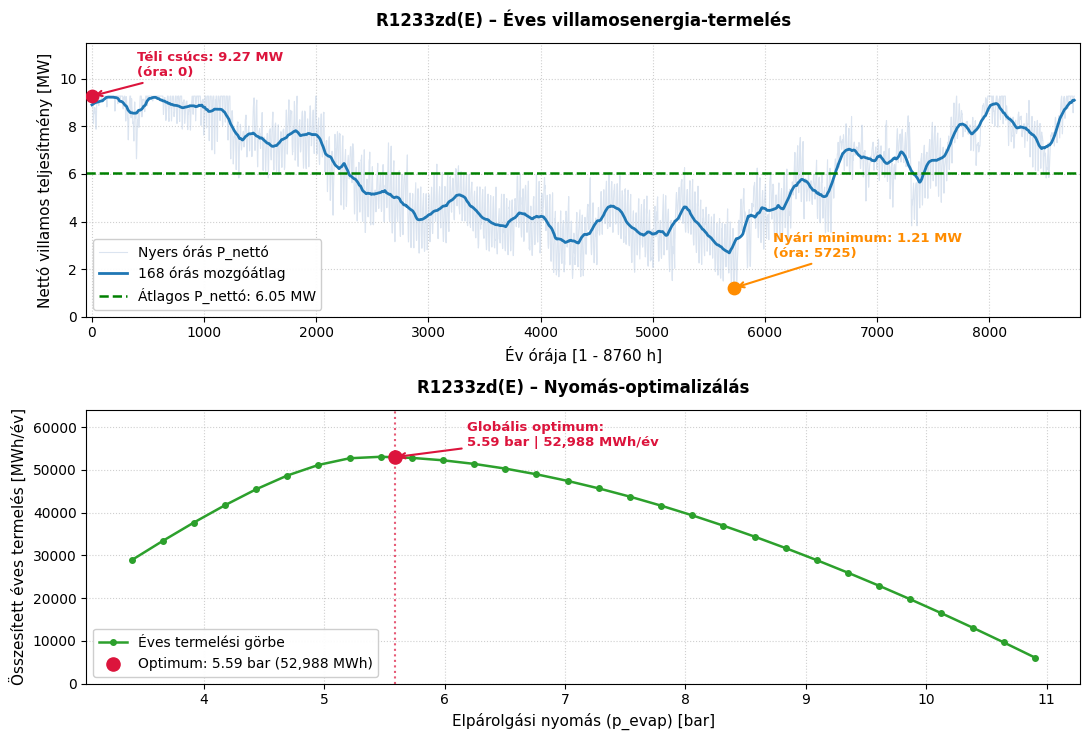

In [37]:
import matplotlib.pyplot as plt

# --- 1. R1233zd(E) adatok és nyomássöprés előkészítése ---
target_fluid = "R1233zd(E)"
p_opt_fluid = comparison_df.loc[target_fluid, "Optimális p_evap [bar]"]
p_hourly_mw = hourly_profiles[target_fluid] / 1000.0  # kW -> MW

p_peak = p_hourly_mw.max()
p_min = p_hourly_mw.min()
p_mean = p_hourly_mw.mean()

idx_peak = int(np.argmax(p_hourly_mw))
idx_min = int(np.argmin(p_hourly_mw))

# --- 2. Grafikonok felépítése ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5))

# --- FELSŐ ÁBRA: Éves teljesítménygörbe ---
ax1.plot(p_hourly_mw, color="#b0c4de", alpha=0.45, lw=0.8, label="Nyers órás P_nettó")
p_smooth = pd.Series(p_hourly_mw).rolling(window=168, min_periods=1, center=True).mean()
ax1.plot(p_smooth, color="#1f77b4", lw=2, label="168 órás mozgóátlag")

# Vízszintes referenciavonal az átlagnak
ax1.axhline(p_mean, color="green", linestyle="--", lw=1.8, 
            label=f"Átlagos P_nettó: {p_mean:.2f} MW")

# Téli csúcs pont és annotáció (doboz nélkül)
ax1.scatter(idx_peak, p_peak, color="crimson", s=80, zorder=5)
ax1.annotate(f"Téli csúcs: {p_peak:.2f} MW\n(óra: {idx_peak})", 
             xy=(idx_peak, p_peak), xytext=(400, 10.1),
             arrowprops=dict(facecolor="crimson", edgecolor="crimson", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="crimson")

# Nyári minimum pont és annotáció (doboz nélkül)
ax1.scatter(idx_min, p_min, color="darkorange", s=80, zorder=5)
ax1.annotate(f"Nyári minimum: {p_min:.2f} MW\n(óra: {idx_min})", 
             xy=(idx_min, p_min), xytext=(idx_min + 350, 2.5),
             arrowprops=dict(facecolor="darkorange", edgecolor="darkorange", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="darkorange")

ax1.set_title(f"{target_fluid} – Éves villamosenergia-termelés", 
              fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("Év órája [1 - 8760 h]", fontsize=11)
ax1.set_ylabel("Nettó villamos teljesítmény [MW]", fontsize=11)
ax1.set_xlim(-50, 8810)
ax1.set_ylim(0, 11.5)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower left", framealpha=0.95)

# --- ALSÓ ÁBRA: Az optimalizálás jelleggörbéje (p_evap söprés) ---
p_crit_bar = PropsSI("PCRIT", target_fluid) / 1e5
p_min_bar = PropsSI("P", "T", 55.0 + 273.15, "Q", 0, target_fluid) / 1e5
p_max_bar = min(p_crit_bar * 0.90, PropsSI("P", "T", 102.0 + 273.15, "Q", 0, target_fluid) / 1e5)
p_curve_sweep = np.linspace(p_min_bar, p_max_bar, 30)

mwh_curve = []
valid_p = []

for p_test in p_curve_sweep:
    p_net_lookup = []
    valid = True
    for t_amb in t_grid:
        out = run_single_hour(target_fluid, p_test, t_amb)
        if out is None:
            valid = False
            break
        p_net_lookup.append(out["P_net_kw"])
    if valid:
        mwh = (np.interp(t_air_series, t_grid, p_net_lookup)).sum() / 1000.0
        mwh_curve.append(mwh)
        valid_p.append(p_test)

opt_mwh = comparison_df.loc[target_fluid, "Éves Termelés [MWh]"]

ax2.plot(valid_p, mwh_curve, color="#2ca02c", marker="o", markersize=4, lw=1.8, label="Éves termelési görbe")
ax2.scatter(p_opt_fluid, opt_mwh, color="crimson", s=90, zorder=5, label=f"Optimum: {p_opt_fluid:.2f} bar ({opt_mwh:,.0f} MWh)")
ax2.axvline(p_opt_fluid, color="crimson", linestyle=":", alpha=0.7)

# Optimum annotáció (doboz nélkül)
ax2.annotate(f"Globális optimum:\n{p_opt_fluid:.2f} bar | {opt_mwh:,.0f} MWh/év", 
             xy=(p_opt_fluid, opt_mwh), xytext=(p_opt_fluid + 0.6, opt_mwh + 2500),
             arrowprops=dict(facecolor="crimson", edgecolor="crimson", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="crimson")

ax2.set_title(f"{target_fluid} – Nyomás-optimalizálás", 
              fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("Elpárolgási nyomás (p_evap) [bar]", fontsize=11)
ax2.set_ylabel("Összesített éves termelés [MWh/év]", fontsize=11)
ax2.set_ylim(0, 64000)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", framealpha=0.95)

plt.tight_layout()
plt.show()

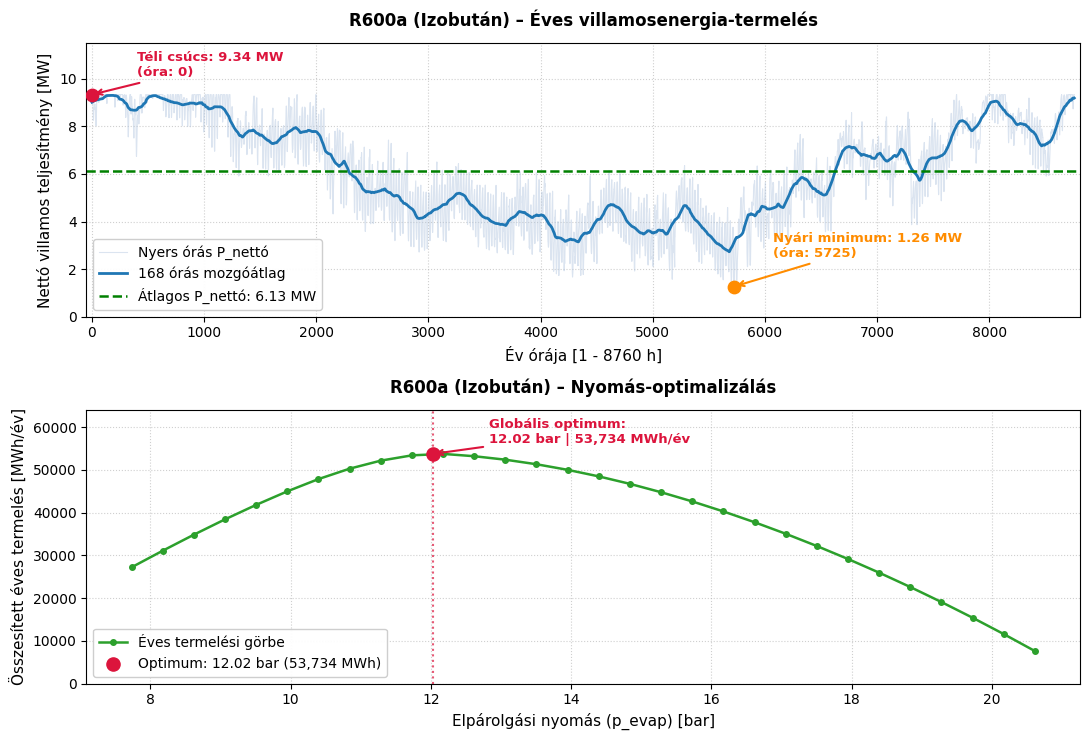

In [38]:
import matplotlib.pyplot as plt

# --- 1. R600a adatok előkészítése ---
target_fluid = "R600a"

# Oszlopnév azonosítása (aláhúzásos és szóközös verziók kezelésére)
col_pevap = [c for c in comparison_df.columns if "p_evap" in c][0]
col_mwh = [c for c in comparison_df.columns if "Termel" in c][0]

p_opt_fluid = float(comparison_df.loc[target_fluid, col_pevap])
opt_mwh = float(comparison_df.loc[target_fluid, col_mwh])

# Órás profil kinyerése a memóriából
p_hourly_mw = hourly_profiles[target_fluid] / 1000.0  # kW -> MW

p_peak = p_hourly_mw.max()
p_min = p_hourly_mw.min()
p_mean = p_hourly_mw.mean()

idx_peak = int(np.argmax(p_hourly_mw))
idx_min = int(np.argmin(p_hourly_mw))

# --- 2. Grafikonok felépítése ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5))

# --- FELSŐ ÁBRA: Éves teljesítménygörbe ---
ax1.plot(p_hourly_mw, color="#b0c4de", alpha=0.45, lw=0.8, label="Nyers órás P_nettó")
p_smooth = pd.Series(p_hourly_mw).rolling(window=168, min_periods=1, center=True).mean()
ax1.plot(p_smooth, color="#1f77b4", lw=2, label="168 órás mozgóátlag")

# Vízszintes referenciavonal az átlagnak
ax1.axhline(p_mean, color="green", linestyle="--", lw=1.8, 
            label=f"Átlagos P_nettó: {p_mean:.2f} MW")

# Téli csúcs pont és felirat
ax1.scatter(idx_peak, p_peak, color="crimson", s=80, zorder=5)
ax1.annotate(f"Téli csúcs: {p_peak:.2f} MW\n(óra: {idx_peak})", 
             xy=(idx_peak, p_peak), xytext=(400, 10.1),
             arrowprops=dict(facecolor="crimson", edgecolor="crimson", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="crimson")

# Nyári minimum pont és felirat
ax1.scatter(idx_min, p_min, color="darkorange", s=80, zorder=5)
ax1.annotate(f"Nyári minimum: {p_min:.2f} MW\n(óra: {idx_min})", 
             xy=(idx_min, p_min), xytext=(idx_min + 350, 2.5),
             arrowprops=dict(facecolor="darkorange", edgecolor="darkorange", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="darkorange")

ax1.set_title(f"{target_fluid} (Izobután) – Éves villamosenergia-termelés", 
              fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("Év órája [1 - 8760 h]", fontsize=11)
ax1.set_ylabel("Nettó villamos teljesítmény [MW]", fontsize=11)
ax1.set_xlim(-50, 8810)
ax1.set_ylim(0, 11.5)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower left", framealpha=0.95)

# --- ALSÓ ÁBRA: Az optimalizálás jelleggörbéje (p_evap söprés) ---
p_crit_bar = PropsSI("PCRIT", target_fluid) / 1e5
p_min_bar = PropsSI("P", "T", 55.0 + 273.15, "Q", 0, target_fluid) / 1e5
p_max_bar = min(p_crit_bar * 0.90, PropsSI("P", "T", 102.0 + 273.15, "Q", 0, target_fluid) / 1e5)
p_curve_sweep = np.linspace(p_min_bar, p_max_bar, 30)

mwh_curve = []
valid_p = []

for p_test in p_curve_sweep:
    p_net_lookup = []
    valid = True
    for t_amb in t_grid:
        out = run_single_hour(target_fluid, p_test, t_amb)
        if out is None:
            valid = False
            break
        p_net_lookup.append(out["P_net_kw"])
    if valid:
        mwh = (np.interp(t_air_series, t_grid, p_net_lookup)).sum() / 1000.0
        mwh_curve.append(mwh)
        valid_p.append(p_test)

ax2.plot(valid_p, mwh_curve, color="#2ca02c", marker="o", markersize=4, lw=1.8, label="Éves termelési görbe")
ax2.scatter(p_opt_fluid, opt_mwh, color="crimson", s=90, zorder=5, label=f"Optimum: {p_opt_fluid:.2f} bar ({opt_mwh:,.0f} MWh)")
ax2.axvline(p_opt_fluid, color="crimson", linestyle=":", alpha=0.7)

# Optimum felirat eltolása
ax2.annotate(f"Globális optimum:\n{p_opt_fluid:.2f} bar | {opt_mwh:,.0f} MWh/év", 
             xy=(p_opt_fluid, opt_mwh), xytext=(p_opt_fluid + 0.8, opt_mwh + 2500),
             arrowprops=dict(facecolor="crimson", edgecolor="crimson", arrowstyle="->", lw=1.5),
             fontsize=9.5, fontweight="bold", color="crimson")

ax2.set_title(f"{target_fluid} (Izobután) – Nyomás-optimalizálás", 
              fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("Elpárolgási nyomás (p_evap) [bar]", fontsize=11)
ax2.set_ylabel("Összesített éves termelés [MWh/év]", fontsize=11)
ax2.set_ylim(0, 64000)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", framealpha=0.95)

plt.tight_layout()
plt.show()

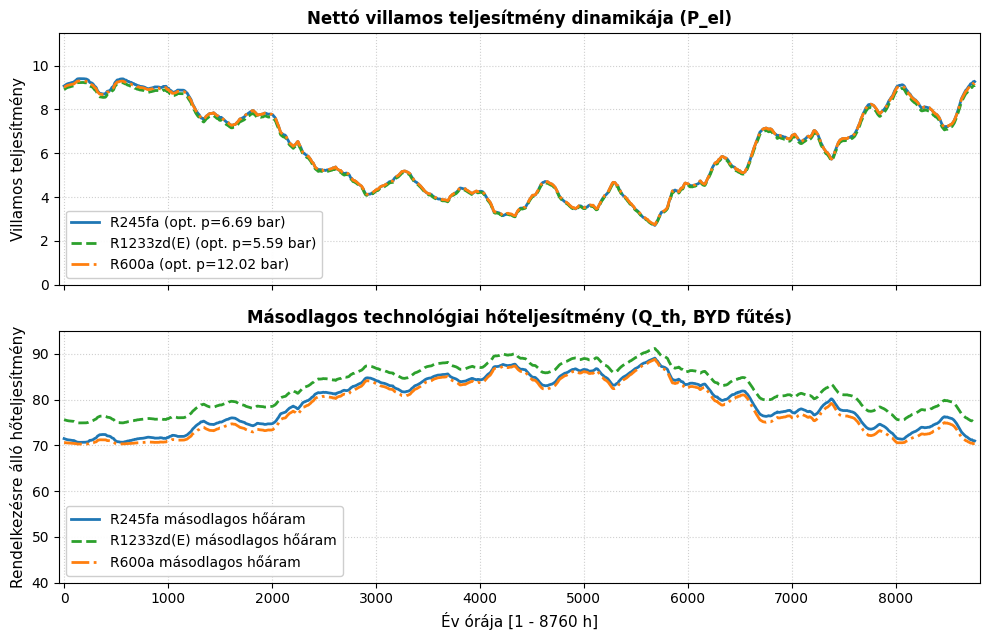

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ha hiányoznának a globális változók:
CP_WATER = 4.184          # kJ/(kg*K)
M_BRINE_TOTAL = 14 * 40.0 # 14 kútpár * 40 kg/s = 560 kg/s
T_INJECTION_C = 35.0      # Másodlagos hűtés alsó határa [°C]

# --- 1. Mindhárom közeg adatainak és hőprofiljának előkészítése ---
col_pevap = [c for c in comparison_df.columns if "p_evap" in c][0]

# Szín- és vonalstílus-beállítások az egyértelmű megkülönböztetéshez
fluid_styles = {
    "R245fa": {"color": "#1f77b4", "linestyle": "-"},
    "R1233zd(E)": {"color": "#2ca02c", "linestyle": "--"},
    "R600a": {"color": "#ff7f0e", "linestyle": "-."},
}

hybrid_profiles = {}

for fluid in DEFAULT_FLUIDS:
    p_opt = float(comparison_df.loc[fluid, col_pevap])
    
    # ORC kilépő vízhőmérséklet (T_brine_out) kiszámítása
    t_brine_lookup = []
    for t_amb in t_grid:
        out = run_single_hour(fluid, p_opt, t_amb)
        t_brine_lookup.append(out["T_brine_out_C"])
    
    hourly_t_brine = np.interp(t_air_series, t_grid, t_brine_lookup)
    
    # Villamos és termikus teljesítmények [MW]
    hourly_p_el_mw = hourly_profiles[fluid] / 1000.0
    hourly_q_heat_mw = (M_BRINE_TOTAL * CP_WATER * (hourly_t_brine - T_INJECTION_C)) / 1000.0
    
    hybrid_profiles[fluid] = {
        "p_el_smooth": pd.Series(hourly_p_el_mw).rolling(168, min_periods=1, center=True).mean(),
        "q_heat_smooth": pd.Series(hourly_q_heat_mw).rolling(168, min_periods=1, center=True).mean(),
        "p_opt": p_opt
    }

# --- 2. Közös, összehasonlító diagram felépítése (2 részdiagram) ---
fig, (ax_el, ax_th) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# --- FELSŐ ÁBRA: Villamos ág (P_el) ---
for fluid, style in fluid_styles.items():
    ax_el.plot(
        hybrid_profiles[fluid]["p_el_smooth"],
        label=f"{fluid} (opt. p={hybrid_profiles[fluid]['p_opt']:.2f} bar)",
        color=style["color"],
        linestyle=style["linestyle"],
        lw=2.0
    )

ax_el.set_title("Nettó villamos teljesítmény dinamikája (P_el)", fontsize=12, fontweight="bold")
ax_el.set_ylabel("Villamos teljesítmény", fontsize=11)
ax_el.set_ylim(0, 11.5)
ax_el.grid(True, linestyle=":", alpha=0.6)
ax_el.legend(loc="lower left", framealpha=0.95)

# --- ALSÓ ÁBRA: Másodlagos technológiai hőteljesítmény (Q_th) ---
for fluid, style in fluid_styles.items():
    ax_th.plot(
        hybrid_profiles[fluid]["q_heat_smooth"],
        label=f"{fluid} másodlagos hőáram",
        color=style["color"],
        linestyle=style["linestyle"],
        lw=2.0
    )

ax_th.set_title("Másodlagos technológiai hőteljesítmény (Q_th, BYD fűtés)", fontsize=12, fontweight="bold")
ax_th.set_xlabel("Év órája [1 - 8760 h]", fontsize=11)
ax_th.set_ylabel("Rendelkezésre álló hőteljesítmény", fontsize=11)
ax_th.set_xlim(-50, 8810)
ax_th.set_ylim(40, 95)
ax_th.grid(True, linestyle=":", alpha=0.6)
ax_th.legend(loc="lower left", framealpha=0.95)

plt.tight_layout()
plt.show()